# International Debt Analysis: Data Cleaning & Exploratory Data Analysis

**Dataset:** World Bank *International Debt Statistics* (`IDS_ALLCountries_Data.csv`, last updated 12/03/2025)

This notebook covers the first three stages of the pipeline:

1. **Data collection:** load the raw CSV into a pandas DataFrame and understand its structure
2. **Data cleaning & preprocessing:** footer rows, duplicates, missing values, data types, reshaping, aggregates
3. **Exploratory data analysis:** country-wise distribution, top and bottom countries, indicators, trends, regions, ratios

The cleaned output is what `src/load_to_mysql.py` inserts into MySQL.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from src import config
from src.cleaning import clean, save

sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

def billions(ax, axis="x"):
    fmt = mtick.FuncFormatter(lambda v, _: f"${v/1e9:,.0f}B")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Data collection

In [2]:
raw = pd.read_csv(config.RAW_DATA_FILE, encoding=config.RAW_ENCODING, low_memory=False)
print("Shape:", raw.shape)
raw.head()

Shape: (62983, 39)


,Country Name,Country Code,Counterpart-Area Name,Counterpart-Area Code,Series Name,Series Code,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032
0,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.DPPG,NaN,NaN,NaN,NaN,NaN,NaN,10.25,8.08,9.96,0.00,7.83,0.00,0.00,0.00,29.83,0.00,0.00,19.84,0.00,17.90,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.OFFT,NaN,NaN,NaN,NaN,NaN,NaN,10.25,8.08,9.96,0.00,7.83,0.00,0.00,0.00,29.83,0.00,0.00,19.84,0.00,17.90,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.PRVT,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,World,WLD,Average grant element on new external debt com...,DT.GRE.DPPG,NaN,NaN,NaN,NaN,NaN,NaN,50.62,43.02,58.01,0.00,21.21,0.00,0.00,0.00,81.93,0.00,0.00,64.26,0.00,73.08,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,World,WLD,Average grant element on new external debt com...,DT.GRE.OFFT,NaN,NaN,NaN,NaN,NaN,NaN,50.62,43.02,58.01,0.00,21.21,0.00,0.00,0.00,81.93,0.00,0.00,64.26,0.00,73.08,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The file is in **wide format**. Each row is one *country × indicator*, and each of the **33 year columns (2000–2032)** holds a value.

The file is **not UTF-8**. It contains non-breaking-space bytes (`0xA0`), so it has to be read as `latin-1`.

In [3]:
raw.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 62983 entries, 0 to 62982
Data columns (total 39 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Country Name           62980 non-null  str    
 1   Country Code           62978 non-null  str    
 2   Counterpart-Area Name  62978 non-null  str    
 3   Counterpart-Area Code  62978 non-null  str    
 4   Series Name            62978 non-null  str    
 5   Series Code            62978 non-null  str    
 6   2000                   49490 non-null  float64
 7   2001                   49434 non-null  float64
 8   2002                   49262 non-null  float64
 9   2003                   49001 non-null  float64
 10  2004                   49195 non-null  float64
 11  2005                   49137 non-null  float64
 12  2006                   49394 non-null  float64
 13  2007                   49645 non-null  float64
 14  2008                   49497 non-null  float64
 15  2009         

In [4]:
year_cols = [c for c in raw.columns if c.strip().isdigit()]
id_cols = [c for c in raw.columns if c not in year_cols]
print("Identifier columns:", id_cols)
print("Year columns      :", year_cols[0], "...", year_cols[-1], f"({len(year_cols)})")
print()
print(raw[id_cols].nunique())

Identifier columns: ['Country Name', 'Country Code', 'Counterpart-Area Name', 'Counterpart-Area Code', 'Series Name', 'Series Code']
Year columns      : 2000 ... 2032 (33)

Country Name             136
Country Code             134
Counterpart-Area Name      1
Counterpart-Area Code      1
Series Name              576
Series Code              576
dtype: int64


In [5]:
# Rows at the bottom of the file are not data
raw.tail(6)[id_cols]

,Country Name,Country Code,Counterpart-Area Name,Counterpart-Area Code,Series Name,Series Code
62977,Zimbabwe,ZWE,World,WLD,"Use of IMF credit and SDR allocations (DOD, cu...",DT.DOD.DIMF.CD
62978,NaN,NaN,NaN,NaN,NaN,NaN
62979,NaN,NaN,NaN,NaN,NaN,NaN
62980,NaN,NaN,NaN,NaN,NaN,NaN
62981,Data from database: International Debt Statistics,NaN,NaN,NaN,NaN,NaN
62982,Last Updated: 12/03/2025,NaN,NaN,NaN,NaN,NaN


## 2. Data quality checks

In [6]:
print("Counterpart-Area values:", raw["Counterpart-Area Name"].dropna().unique())
print("Country codes with padding:", (raw["Country Code"].dropna().str.len() > 3).sum())
print("Full duplicate rows:", raw.duplicated().sum(), "(all of them are the blank footer lines)")
print("Duplicate country+series keys (excluding footer):",
      raw.dropna(subset=["Series Code"]).duplicated(["Country Code", "Series Code"]).sum())

Counterpart-Area values: <ArrowStringArray>
['World']
Length: 1, dtype: str
Country codes with padding: 62978
Full duplicate rows: 2 (all of them are the blank footer lines)


Duplicate country+series keys (excluding footer): 0


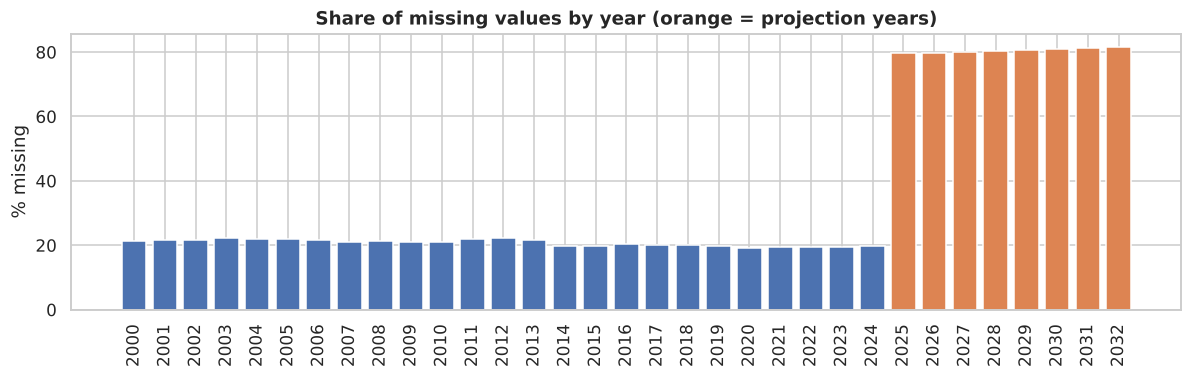

Overall missing: 35.3%


In [7]:
data_rows = raw.dropna(subset=["Series Code"])
miss = data_rows[year_cols].isna().mean().mul(100)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(miss.index, miss.values, color=["#4c72b0" if int(y) <= config.LATEST_ACTUAL_YEAR else "#dd8452" for y in miss.index])
ax.set_title("Share of missing values by year (orange = projection years)")
ax.set_ylabel("% missing"); ax.tick_params(axis="x", rotation=90)
savefig("01_missing_by_year")
print(f"Overall missing: {data_rows[year_cols].isna().mean().mean()*100:.1f}%")

**Observations**

- **About 19–22% of values are missing in each actual year (2000–2024).** Not every country reports every indicator.
- **About 80–82% of values are missing in 2025–2032.** Those years only hold *projected* principal and interest payments on existing debt.
- A missing debt figure means *"not reported"*. Treating it as zero would be wrong, so missing values are **dropped, not imputed**.
- `Counterpart-Area` is always "World", so it adds nothing and is dropped.
- `Country Code` is padded with spaces, which need stripping.
- The bottom 5 rows are blank lines or notes ("Data from database…", "Last Updated…").

## 3. Cleaning & preprocessing

All the cleaning logic lives in `src/cleaning.py`, so the notebook, the loader and the dashboard share exactly one definition. Here we run it and look at what it did.

In [8]:
result = clean()
save(result)
report = result["report"]
print(json.dumps({k: v for k, v in report.items() if k not in ("aggregates",)}, indent=2, default=str))

{
  "raw_shape": [
    62983,
    39
  ],
  "year_columns": [
    2000,
    2032
  ],
  "footer_or_blank_rows_dropped": 5,
  "counterpart_area_values": [
    "World"
  ],
  "duplicate_rows_removed": 0,
  "duplicate_keys_removed": 0,
  "cells_total": 2078274,
  "cells_missing": 733228,
  "missing_pct": 35.28,
  "rows_with_no_data_at_all": 3340,
  "long_rows_before_dropna": 2078274,
  "long_rows_after_dropna": 1345046,
  "countries_without_income_group": [
    "Ethiopia"
  ],
  "countries": 120,
  "indicators": 576,
  "indicators_by_unit": {
    "USD": 541,
    "Percent": 27,
    "Years": 6,
    "Other": 2
  },
  "fact_rows": 1345046,
  "projection_rows": 98111,
  "global_external_debt_latest_usd": 8939920662152.0,
  "components_sum_latest_usd": 8944716144050.102,
  "components_match_total": true
}


In [9]:
countries, indicators, debt = result["countries"], result["indicators"], result["debt_data"]
print("Aggregates (excluded from country analysis):")
print(", ".join(report["aggregates"]))
countries.head()

Aggregates (excluded from country analysis):
East Asia & Pacific (excluding high income), Europe & Central Asia (excluding high income), IDA only, IDA total, Latin America & Caribbean (excluding high income), Least developed countries: UN classification, Low & middle income, Low income, Lower middle income, Middle East, North Africa, Afghanistan & Pakistan (excluding high income), Middle income, South Asia, Sub-Saharan Africa (excluding high income), Upper middle income


,country_id,country_code,country_name,region,income_group,lending_category,is_aggregate
0,1,AFG,Afghanistan,Middle East & North Africa,Low income,IDA,0
1,2,ALB,Albania,Europe & Central Asia,Upper middle income,IBRD,0
2,3,DZA,Algeria,Middle East & North Africa,Upper middle income,IBRD,0
3,4,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,0
4,5,ARG,Argentina,Latin America & Caribbean,Upper middle income,IBRD,0


In [10]:
indicators[["indicator_code", "indicator_name", "unit", "category"]].sample(6, random_state=1)

,indicator_code,indicator_name,unit,category
261,DT.DXR.DPPG.CD,Debt stock rescheduled (current US$),USD,Other (US$)
547,DT.TDS.PCBK.CD,"PPG, commercial banks (TDS, current US$)",USD,Total debt service
267,DT.GRE.PRVT,Average grant element on new external debt com...,Percent,Ratio / percentage
541,DT.TDS.PBND.CD,"PPG, bonds (TDS, current US$)",USD,Total debt service
460,DT.NTR.MLTC.CD,"PPG, multilateral concessional (NTR, current US$)",USD,Net transfers
285,DT.INT.DECT.EX.ZS,Interest payments on external debt (% of expor...,Percent,Ratio / percentage


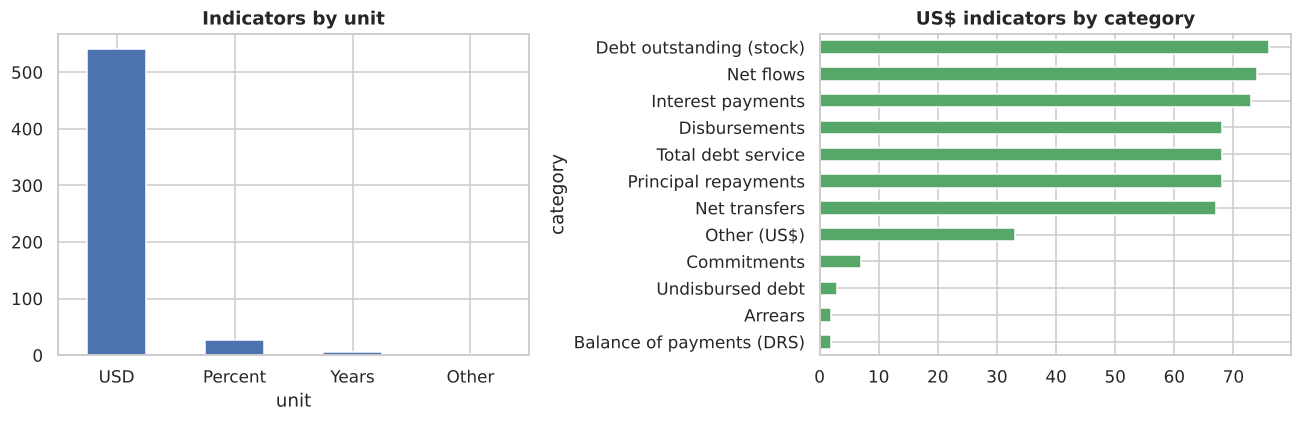

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
indicators["unit"].value_counts().plot.bar(ax=ax[0], color="#4c72b0")
ax[0].set_title("Indicators by unit"); ax[0].tick_params(axis="x", rotation=0)
(indicators[indicators.unit == "USD"]["category"].value_counts()
    .sort_values().plot.barh(ax=ax[1], color="#55a868"))
ax[1].set_title("US$ indicators by category")
savefig("02_indicator_types")

**Why "debt" needs a precise definition.** The 576 indicators overlap. *External debt stocks, total* already contains *long-term*, *short-term*, *PPG* and so on, so summing every indicator would count the same dollar many times.

This project defines:

- **A country's debt** as *External debt stocks, total (DOD, current US$)*, code `DT.DOD.DECT.CD`
- **Its composition** as 4 non-overlapping components: public and publicly guaranteed (PPG), private non-guaranteed (PNG), short-term, and IMF credit

The check below confirms that the components add up to the total.

In [12]:
print(f"Total external debt, 120 countries, {config.LATEST_ACTUAL_YEAR}: ${report['global_external_debt_latest_usd']/1e12:,.3f} T")
print(f"Sum of the 4 components                  : ${report['components_sum_latest_usd']/1e12:,.3f} T")
print("Components match total:", report["components_match_total"])

Total external debt, 120 countries, 2024: $8.940 T
Sum of the 4 components                  : $8.945 T
Components match total: True


## 4. Exploratory data analysis

In [13]:
ind = indicators.set_index("indicator_code")["indicator_id"]
cty = countries[countries.is_aggregate == 0]

def series(code, actual_only=True):
    """Long table (country, year, value) for one indicator, countries only."""
    s = debt[(debt.indicator_id == ind[code]) & debt.country_id.isin(cty.country_id)]
    if actual_only:
        s = s[s.is_projection == 0]
    return s.merge(cty, on="country_id")[["country_name", "country_code", "region", "income_group", "year", "value"]]

total = series(config.TOTAL_DEBT_CODE)
latest = total[total.year == config.LATEST_ACTUAL_YEAR].sort_values("value", ascending=False).reset_index(drop=True)
print(f"Countries with {config.LATEST_ACTUAL_YEAR} data: {len(latest)}")
latest["value"].describe().to_frame("total_external_debt_usd")

Countries with 2024 data: 120


,total_external_debt_usd
count,120.00
mean,"74,499,338,851.27"
std,"247,067,829,846.92"
min,"173,176,112.10"
25%,"3,417,750,563.00"
50%,"12,845,688,040.00"
75%,"43,906,105,439.75"
max,"2,420,000,000,000.00"


### 4.1 Global debt trend (2000–2024)

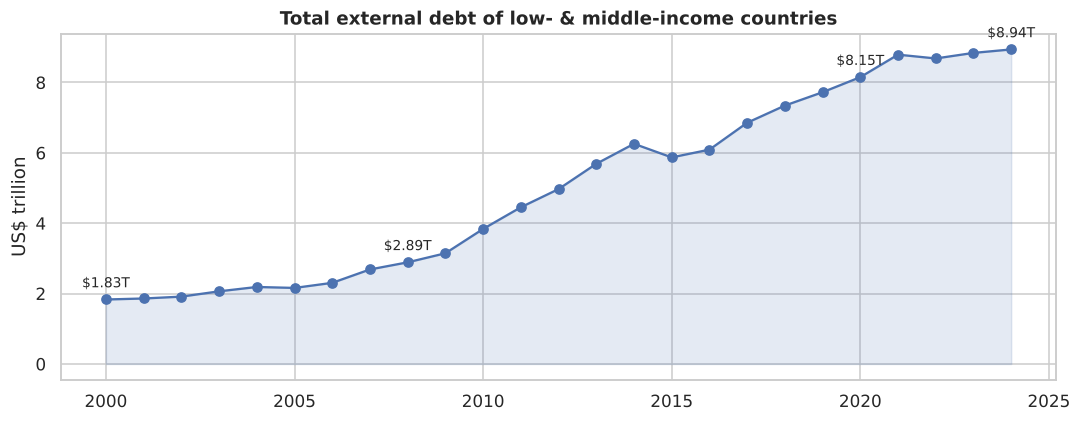

2000: $1.83T -> 2024: $8.94T  (4.9x, CAGR 6.8%)
Peak year: 2024 ($8.94T)


In [14]:
glob = total.groupby("year")["value"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(glob.index, glob.values / 1e12, marker="o", color="#4c72b0")
ax.fill_between(glob.index, glob.values / 1e12, alpha=.15, color="#4c72b0")
ax.set_title("Total external debt of low- & middle-income countries")
ax.set_ylabel("US$ trillion")
for y in (2000, 2008, 2020, 2024):
    ax.annotate(f"${glob[y]/1e12:.2f}T", (y, glob[y]/1e12), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
savefig("03_global_trend")
cagr = (glob[2024] / glob[2000]) ** (1 / 24) - 1
print(f"2000: ${glob[2000]/1e12:.2f}T -> 2024: ${glob[2024]/1e12:.2f}T  ({glob[2024]/glob[2000]:.1f}x, CAGR {cagr*100:.1f}%)")
print(f"Peak year: {glob.idxmax()} (${glob.max()/1e12:.2f}T)")

### 4.2 Countries with the highest and lowest debt

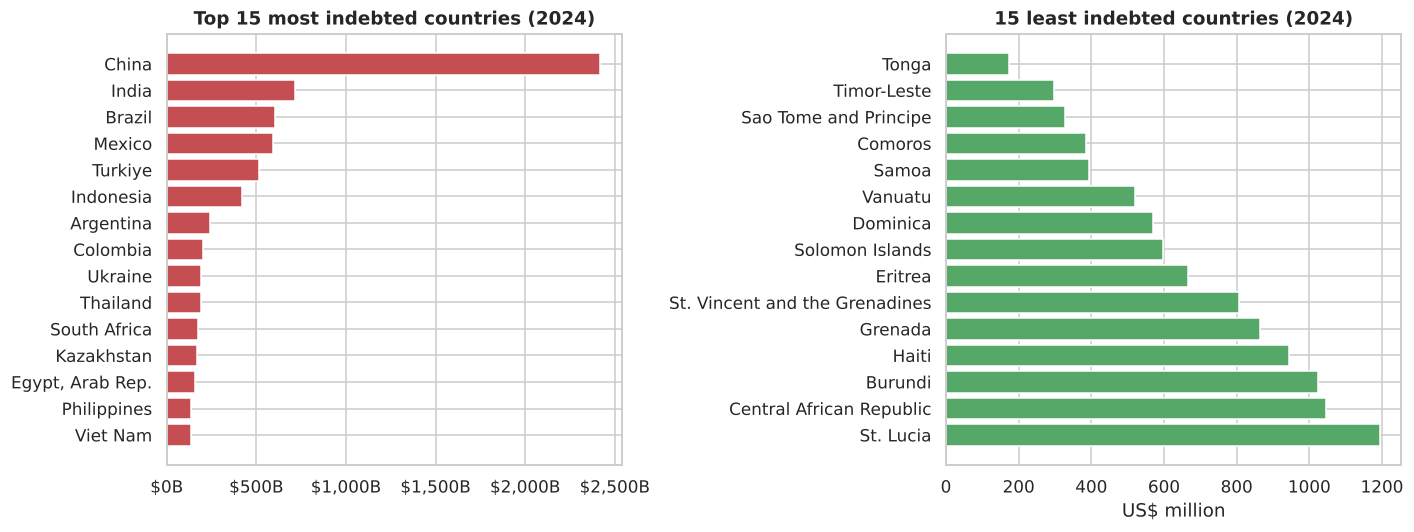

,country_name,region,income_group,value
0,China,East Asia & Pacific,Upper middle income,"2,420,000,000,000.00"
1,India,South Asia,Lower middle income,"716,000,000,000.00"
2,Brazil,Latin America & Caribbean,Upper middle income,"605,000,000,000.00"
3,Mexico,Latin America & Caribbean,Upper middle income,"591,000,000,000.00"
4,Turkiye,Europe & Central Asia,Upper middle income,"515,000,000,000.00"
5,Indonesia,East Asia & Pacific,Upper middle income,"421,000,000,000.00"
6,Argentina,Latin America & Caribbean,Upper middle income,"242,000,000,000.00"
7,Colombia,Latin America & Caribbean,Upper middle income,"202,000,000,000.00"
8,Ukraine,Europe & Central Asia,Upper middle income,"193,000,000,000.00"
9,Thailand,East Asia & Pacific,Upper middle income,"192,000,000,000.00"


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
top = latest.head(15).iloc[::-1]
ax[0].barh(top.country_name, top.value, color="#c44e52"); billions(ax[0])
ax[0].set_title(f"Top 15 most indebted countries ({config.LATEST_ACTUAL_YEAR})")
bot = latest.tail(15)
ax[1].barh(bot.country_name, bot.value / 1e6, color="#55a868")
ax[1].set_title(f"15 least indebted countries ({config.LATEST_ACTUAL_YEAR})"); ax[1].set_xlabel("US$ million")
savefig("04_top_bottom_countries")
latest.head(10)[["country_name", "region", "income_group", "value"]]

In [16]:
latest.tail(5)[["country_name", "region", "income_group", "value"]]

,country_name,region,income_group,value
115,Samoa,East Asia & Pacific,Upper middle income,"394,938,377.50"
116,Comoros,Sub-Saharan Africa,Lower middle income,"385,570,286.60"
117,Sao Tome and Principe,Sub-Saharan Africa,Lower middle income,"326,406,625.80"
118,Timor-Leste,East Asia & Pacific,Lower middle income,"296,673,869.10"
119,Tonga,East Asia & Pacific,Upper middle income,"173,176,112.10"


### 4.3 Distribution and concentration

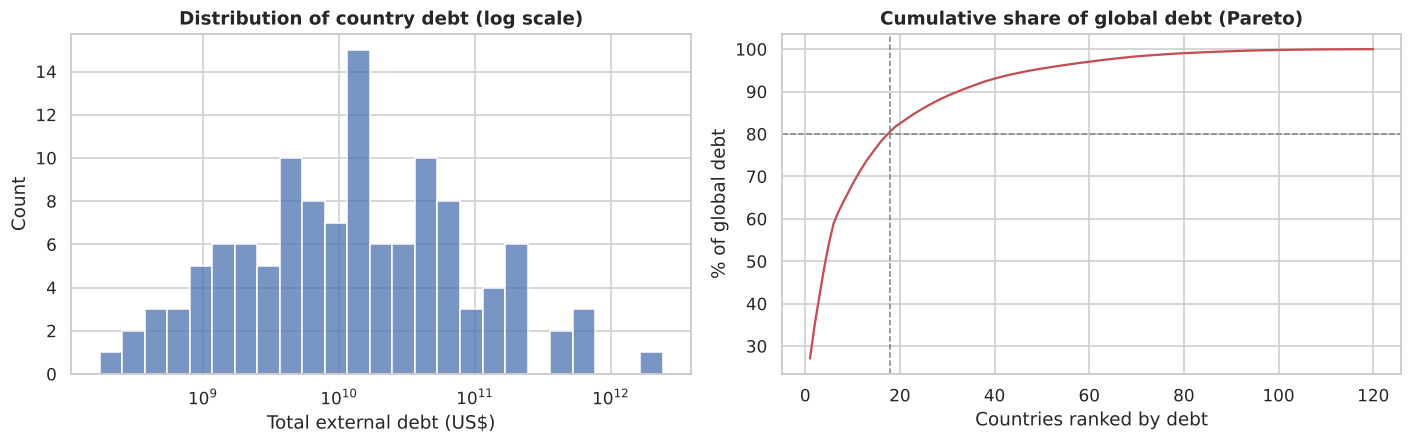

Mean $74.5B vs median $12.8B (strong right skew, skewness 7.7)
China alone: 27.1% | top 5: 54.2% | top 10: 68.2%
18 of 120 countries hold 80% of the debt


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(latest.value, log_scale=True, bins=25, ax=ax[0], color="#4c72b0")
ax[0].set_title("Distribution of country debt (log scale)"); ax[0].set_xlabel("Total external debt (US$)")
cum = latest.value.cumsum() / latest.value.sum() * 100
ax[1].plot(range(1, len(cum) + 1), cum.values, color="#c44e52")
ax[1].axhline(80, ls="--", c="grey", lw=1)
n80 = int((cum < 80).sum()) + 1
ax[1].axvline(n80, ls="--", c="grey", lw=1)
ax[1].set_title("Cumulative share of global debt (Pareto)")
ax[1].set_xlabel("Countries ranked by debt"); ax[1].set_ylabel("% of global debt")
savefig("05_distribution_pareto")
print(f"Mean ${latest.value.mean()/1e9:,.1f}B vs median ${latest.value.median()/1e9:,.1f}B (strong right skew, skewness {latest.value.skew():.1f})")
print(f"China alone: {latest.value.iloc[0]/latest.value.sum()*100:.1f}% | top 5: {cum.iloc[4]:.1f}% | top 10: {cum.iloc[9]:.1f}%")
print(f"{n80} of {len(latest)} countries hold 80% of the debt")

### 4.4 Regions and income groups

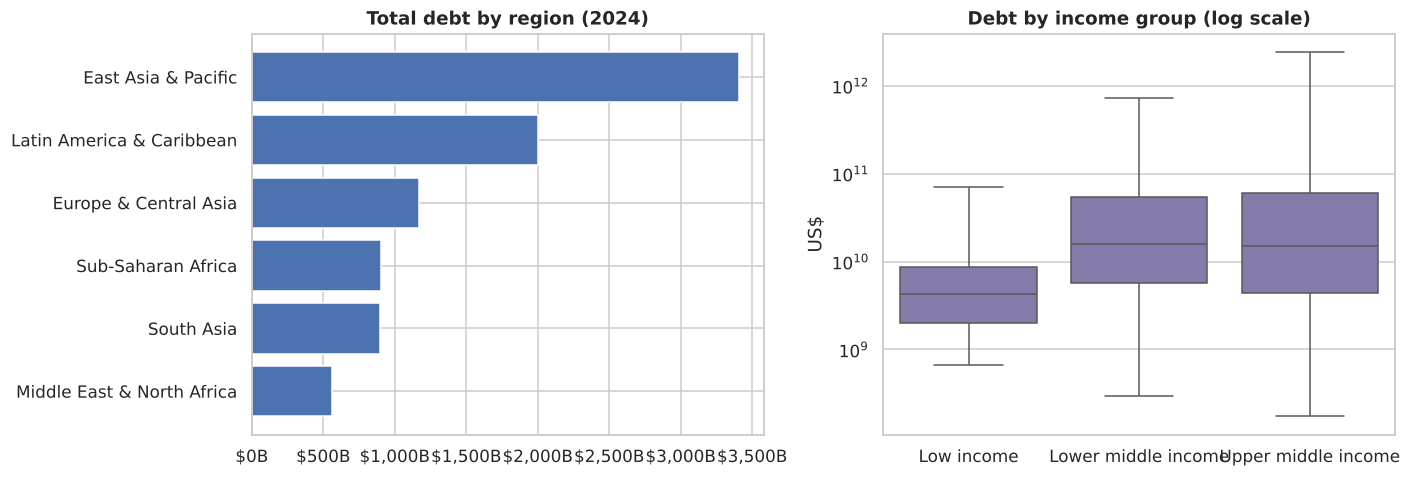

,sum,count,median,share_pct
region,,,,
East Asia & Pacific,"3,409,709,286,050.80",16,"15,345,420,854.00",38.14
Latin America & Caribbean,"2,003,247,127,280.30",22,"15,604,058,793.50",22.41
Europe & Central Asia,"1,169,269,857,231.00",18,"13,362,853,534.00",13.08
Sub-Saharan Africa,"901,132,384,164.90",45,"6,653,640,488.00",10.08
South Asia,"895,072,235,574.00",6,"33,489,842,860.00",10.01
Middle East & North Africa,"561,489,771,851.00",13,"17,517,006,333.00",6.28


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
reg = latest.groupby("region")["value"].agg(["sum", "count", "median"]).sort_values("sum")
ax[0].barh(reg.index, reg["sum"], color="#4c72b0"); billions(ax[0]); ax[0].set_title("Total debt by region (2024)")
order = ["Low income", "Lower middle income", "Upper middle income"]
sns.boxplot(data=latest, x="income_group", y="value", order=order, ax=ax[1], color="#8172b2", log_scale=True)
ax[1].set_title("Debt by income group (log scale)"); ax[1].set_xlabel(""); ax[1].set_ylabel("US$")
savefig("06_region_income")
reg.assign(share_pct=reg["sum"] / reg["sum"].sum() * 100).sort_values("sum", ascending=False)

### 4.5 Debt composition: who is the debt owed by?

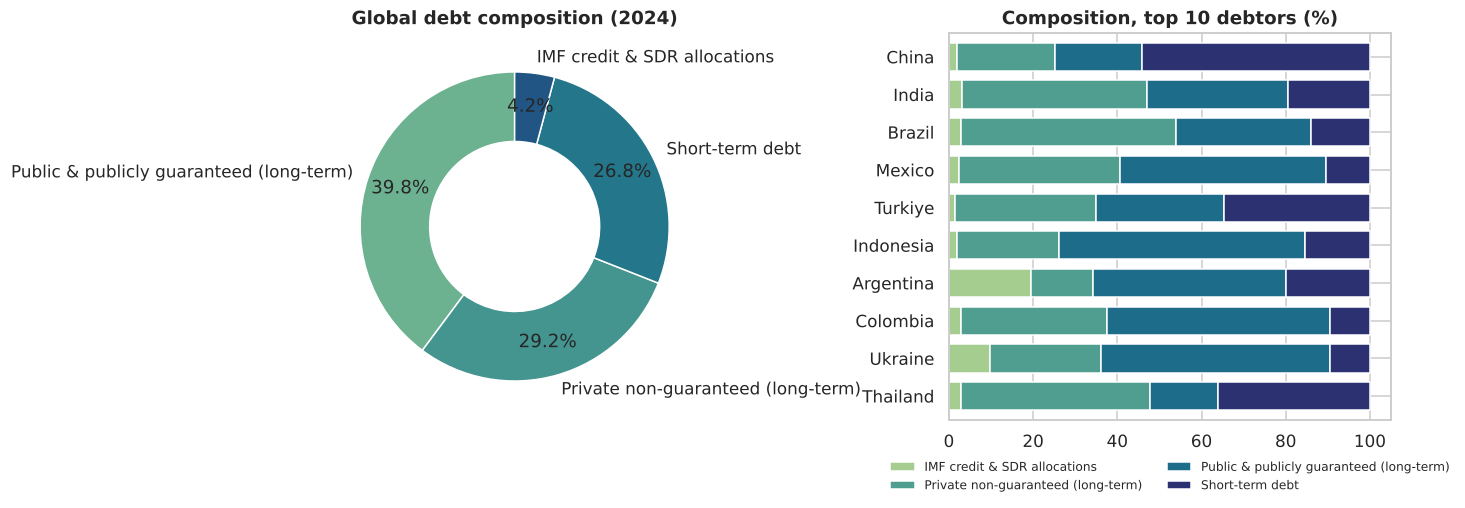

,share_%
component,
Public & publicly guaranteed (long-term),39.80
Private non-guaranteed (long-term),29.20
Short-term debt,26.80
IMF credit & SDR allocations,4.20


In [19]:
comp = pd.concat([series(c).assign(component=name) for c, name in config.DEBT_COMPONENT_CODES.items()])
comp_l = comp[comp.year == config.LATEST_ACTUAL_YEAR]
glob_comp = comp_l.groupby("component")["value"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].pie(glob_comp, labels=glob_comp.index, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
          colors=sns.color_palette("crest", 4), wedgeprops={"width": .45})
ax[0].set_title("Global debt composition (2024)")
top10 = latest.head(10).country_name
piv = (comp_l[comp_l.country_name.isin(top10)].pivot_table(index="country_name", columns="component", values="value")
       .reindex(top10[::-1]))
(piv.div(piv.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, ax=ax[1], colormap="crest", width=.75)
ax[1].set_title("Composition, top 10 debtors (%)"); ax[1].set_ylabel("")
ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
savefig("07_composition")
(glob_comp / glob_comp.sum() * 100).round(1).to_frame("share_%")

In [20]:
dom = (comp_l.sort_values("value", ascending=False).groupby("country_name").head(1)
       ["component"].value_counts().to_frame("countries where it is the largest component"))
dom

,countries where it is the largest component
component,
Public & publicly guaranteed (long-term),101
Private non-guaranteed (long-term),11
Short-term debt,4
IMF credit & SDR allocations,4


### 4.6 Indicators: flows and debt service

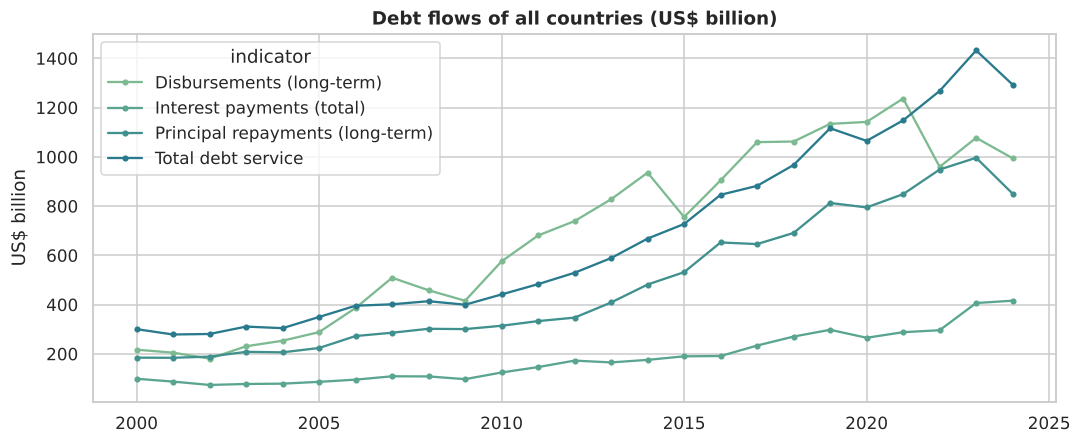

indicator,Disbursements (long-term),Interest payments (total),Principal repayments (long-term),Total debt service
year,,,,
2010,575.60,124.30,314.00,441.30
2020,"1,141.80",265.20,794.60,"1,064.70"
2024,994.30,415.70,850.40,"1,293.00"


In [21]:
flow_codes = {"DT.DIS.DLXF.CD": "Disbursements (long-term)", "DT.AMT.DLXF.CD": "Principal repayments (long-term)",
              "DT.INT.DECT.CD": "Interest payments (total)", "DT.TDS.DECT.CD": "Total debt service"}
flows = pd.concat([series(c).assign(indicator=n) for c, n in flow_codes.items()])
ft = flows.pivot_table(index="year", columns="indicator", values="value", aggfunc="sum") / 1e9
fig, ax = plt.subplots(figsize=(10, 4.2))
ft.plot(ax=ax, marker=".")
ax.set_title("Debt flows of all countries (US$ billion)"); ax.set_ylabel("US$ billion"); ax.set_xlabel("")
savefig("08_flows_trend")
ft.loc[[2010, 2020, 2024]].round(1)

In [22]:
int_growth = ft.loc[2024, "Interest payments (total)"] / ft.loc[2020, "Interest payments (total)"] - 1
print(f"Interest payments grew {int_growth*100:.0f}% between 2020 and 2024")

Interest payments grew 57% between 2020 and 2024


### 4.7 Debt burden relative to the economy

The largest debt in dollars doesn't always mean the heaviest burden. Debt relative to GNI shows how heavy it is for each economy.

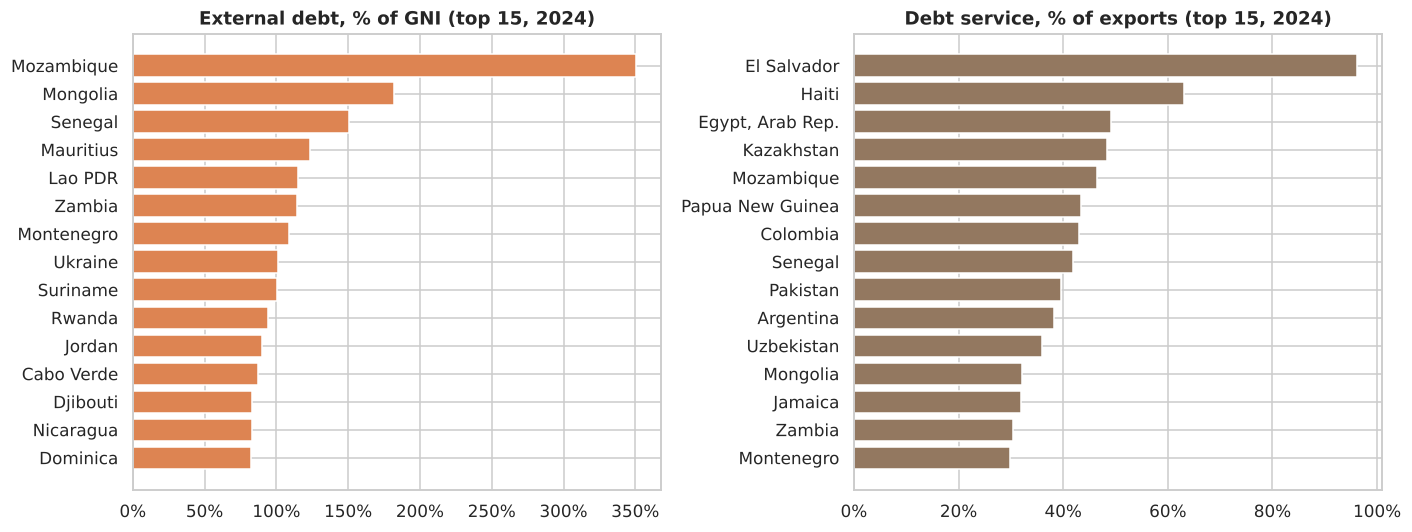

Median debt/GNI: 43.9%  |  countries above 100% of GNI: 9


In [23]:
gni = series("DT.DOD.DECT.GN.ZS")
gni_l = gni[gni.year == config.LATEST_ACTUAL_YEAR].sort_values("value", ascending=False)
dse = series("DT.TDS.DECT.EX.ZS")
dse_l = dse[dse.year == config.LATEST_ACTUAL_YEAR].sort_values("value", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
g = gni_l.head(15).iloc[::-1]
ax[0].barh(g.country_name, g.value, color="#dd8452"); ax[0].set_title("External debt, % of GNI (top 15, 2024)")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter())
d = dse_l.head(15).iloc[::-1]
ax[1].barh(d.country_name, d.value, color="#937860"); ax[1].set_title("Debt service, % of exports (top 15, 2024)")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter())
savefig("09_burden_ratios")
print(f"Median debt/GNI: {gni_l.value.median():.1f}%  |  countries above 100% of GNI: {(gni_l.value > 100).sum()}")

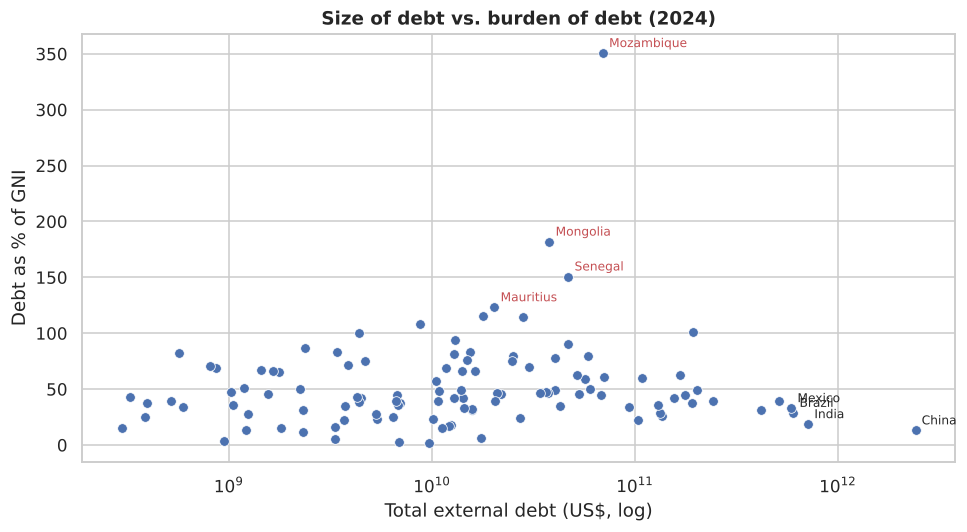

Correlation (log debt vs debt/GNI): 0.11


In [24]:
both = latest[["country_name", "value"]].merge(gni_l[["country_name", "value"]], on="country_name", suffixes=("_usd", "_gni_pct"))
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=both, x="value_usd", y="value_gni_pct", ax=ax, s=40, color="#4c72b0")
ax.set_xscale("log"); ax.set_xlabel("Total external debt (US$, log)"); ax.set_ylabel("Debt as % of GNI")
for _, r in both.nlargest(4, "value_usd").iterrows():
    ax.annotate(r.country_name, (r.value_usd, r.value_gni_pct), fontsize=8, xytext=(4, 4), textcoords="offset points")
for _, r in both.nlargest(4, "value_gni_pct").iterrows():
    ax.annotate(r.country_name, (r.value_usd, r.value_gni_pct), fontsize=8, xytext=(4, 4), textcoords="offset points", color="#c44e52")
ax.set_title("Size of debt vs. burden of debt (2024)")
savefig("10_size_vs_burden")
print(f"Correlation (log debt vs debt/GNI): {np.corrcoef(np.log(both.value_usd), both.value_gni_pct)[0,1]:.2f}")

### 4.8 Growth: whose debt rose fastest?

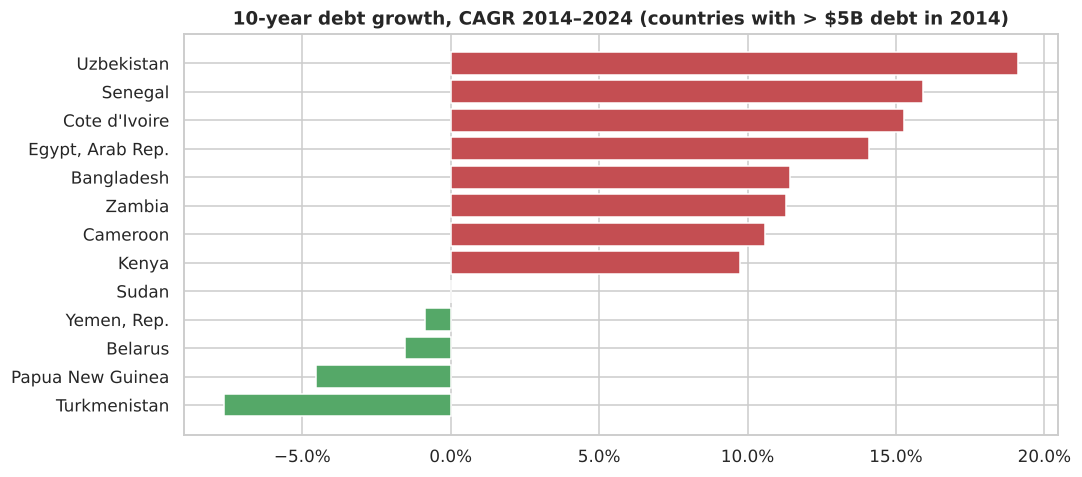

,debt_2014,debt_2024,cagr_pct
country_name,,,
Uzbekistan,"12,218,877,369.00","70,256,401,084.00",19.11
Senegal,"10,754,111,101.00","47,146,494,530.00",15.93
Cote d'Ivoire,"9,803,934,266.00","40,560,965,965.00",15.26
"Egypt, Arab Rep.","41,772,774,971.00","156,000,000,000.00",14.08
Bangladesh,"35,271,839,355.00","104,000,000,000.00",11.42
Zambia,"9,650,598,727.00","28,117,735,301.00",11.29
Cameroon,"5,765,541,169.00","15,770,789,430.00",10.59
Kenya,"16,911,742,537.00","42,886,127,218.00",9.75


In [25]:
w = total.pivot_table(index="country_name", columns="year", values="value")
growth = pd.DataFrame({"debt_2014": w[2014], "debt_2024": w[2024]}).dropna()
growth = growth[growth.debt_2014 > 5e9]          # ignore very small bases
growth["cagr_pct"] = ((growth.debt_2024 / growth.debt_2014) ** (1 / 10) - 1) * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
g = pd.concat([growth.nlargest(8, "cagr_pct"), growth.nsmallest(5, "cagr_pct")]).sort_values("cagr_pct")
ax.barh(g.index, g.cagr_pct, color=np.where(g.cagr_pct > 0, "#c44e52", "#55a868"))
ax.set_title("10-year debt growth, CAGR 2014–2024 (countries with > $5B debt in 2014)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
savefig("11_growth")
growth.sort_values("cagr_pct", ascending=False).head(8)

### 4.9 Relationships between indicators

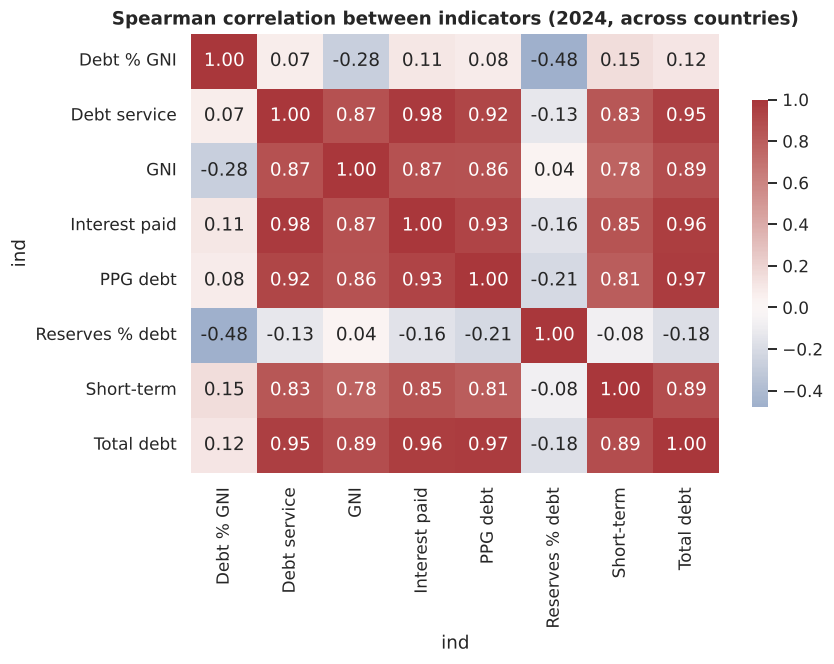

In [26]:
codes = {"DT.DOD.DECT.CD": "Total debt", "DT.DOD.DPPG.CD": "PPG debt", "DT.DOD.DSTC.CD": "Short-term",
         "DT.INT.DECT.CD": "Interest paid", "DT.TDS.DECT.CD": "Debt service", "NY.GNP.MKTP.CD": "GNI",
         "DT.DOD.DECT.GN.ZS": "Debt % GNI", "FI.RES.TOTL.DT.ZS": "Reserves % debt"}
mat = (pd.concat([series(c).assign(ind=n) for c, n in codes.items()])
       .query("year == @config.LATEST_ACTUAL_YEAR")
       .pivot_table(index="country_name", columns="ind", values="value"))
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(mat.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Spearman correlation between indicators (2024, across countries)")
savefig("12_correlation")

### 4.10 Projected debt service (2025–2032)

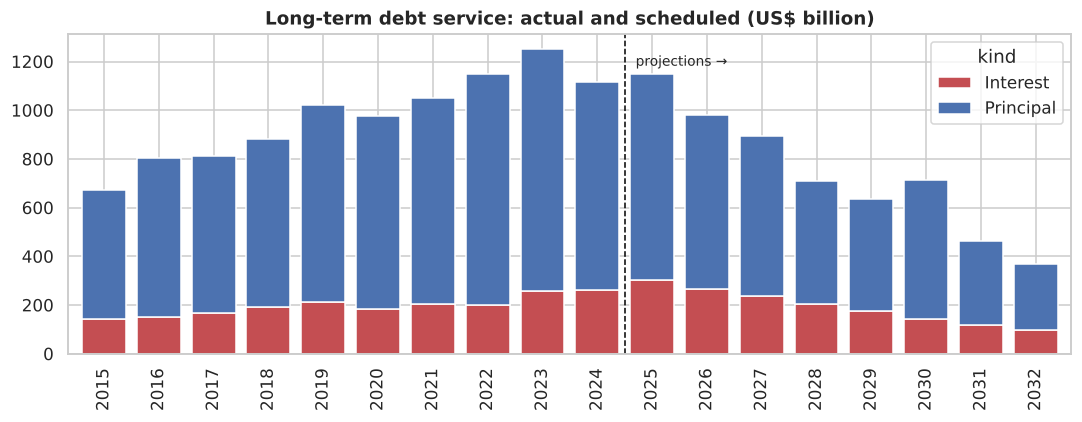

In [27]:
proj = debt[(debt.indicator_id.isin([ind["DT.AMT.DLXF.CD"], ind["DT.INT.DLXF.CD"]])) & debt.country_id.isin(cty.country_id)]
proj = proj.merge(indicators[["indicator_id", "indicator_code"]]).assign(
    kind=lambda x: x.indicator_code.map({"DT.AMT.DLXF.CD": "Principal", "DT.INT.DLXF.CD": "Interest"}))
pt = proj.pivot_table(index="year", columns="kind", values="value", aggfunc="sum").loc[2015:] / 1e9
fig, ax = plt.subplots(figsize=(10, 4))
pt.plot.bar(stacked=True, ax=ax, color=["#c44e52", "#4c72b0"], width=.8)
ax.axvline(pt.index.get_loc(2024) + .5, color="k", ls="--", lw=1)
ax.text(pt.index.get_loc(2024) + .7, ax.get_ylim()[1] * .9, "projections →", fontsize=9)
ax.set_title("Long-term debt service: actual and scheduled (US$ billion)"); ax.set_xlabel("")
savefig("13_projections")

Projections only cover repayments already scheduled on **existing** debt. New borrowing isn't included, so the decline after 2025 isn't a forecast of falling debt service. What it does show is that **2025–2027 carry the heaviest scheduled repayments**.

In [28]:
print("Scheduled long-term debt service, 2025:", f"${pt.loc[2025].sum():,.0f}B", "| actual 2024:", f"${pt.loc[2024].sum():,.0f}B")

Scheduled long-term debt service, 2025: $1,148B | actual 2024: $1,114B


## 5. Key insights

The numbers below are printed from the data in this notebook.

In [29]:
r = latest
top10_share = r.value.head(10).sum() / r.value.sum() * 100
print(f"1. Total external debt of the 120 reporting countries reached ${glob[2024]/1e12:.2f}T in 2024, "
      f"{glob[2024]/glob[2000]:.1f}x the 2000 level and the highest point in the series.")
print(f"2. Debt is highly concentrated: China holds {r.value.iloc[0]/r.value.sum()*100:.1f}%; the top 10 hold {top10_share:.1f}%; "
      f"{n80} countries account for 80%.")
print(f"3. Highest: {', '.join(r.country_name.head(5))}.  Lowest: {', '.join(r.country_name.tail(3))}.")
print(f"4. By region, {reg['sum'].idxmax()} owes the most ({reg['sum'].max()/reg['sum'].sum()*100:.0f}% of the total).")
print(f"5. Composition: {glob_comp.index[0]} is the largest component ({glob_comp.iloc[0]/glob_comp.sum()*100:.0f}%).")
stock_growth = glob[2024] / glob[2020] - 1
print(f"6. Interest payments rose {int_growth*100:.0f}% from 2020 to 2024, while the debt stock grew only {stock_growth*100:.0f}%. "
      "The interest paid per dollar owed has risen sharply, so servicing debt costs much more than before.")
print(f"7. In dollars, big economies dominate, but relative to GNI the heaviest burdens are in "
      f"{', '.join(gni_l.country_name.head(3))} ({(gni_l.value > 100).sum()} countries owe more than 100% of GNI).")
print(f"8. Fastest 10-year growth (CAGR 2014-24): {', '.join(growth.nlargest(3, 'cagr_pct').index)}.")

1. Total external debt of the 120 reporting countries reached $8.94T in 2024, 4.9x the 2000 level and the highest point in the series.
2. Debt is highly concentrated: China holds 27.1%; the top 10 hold 68.2%; 18 countries account for 80%.
3. Highest: China, India, Brazil, Mexico, Turkiye.  Lowest: Sao Tome and Principe, Timor-Leste, Tonga.
4. By region, East Asia & Pacific owes the most (38% of the total).
5. Composition: Public & publicly guaranteed (long-term) is the largest component (40%).
6. Interest payments rose 57% from 2020 to 2024, while the debt stock grew only 10%. The interest paid per dollar owed has risen sharply, so servicing debt costs much more than before.
7. In dollars, big economies dominate, but relative to GNI the heaviest burdens are in Mozambique, Mongolia, Senegal (9 countries owe more than 100% of GNI).
8. Fastest 10-year growth (CAGR 2014-24): Uzbekistan, Senegal, Cote d'Ivoire.
